# Prediccion de Cultivos

Lucho Dic| 2023 <br>
New Genesis by ADO

### Detalles:
Predecir el rendimiento en condiciones desconocidas y novedosas es uno de los principales problemas en la producción agrícola. El tiempo y el dinero necesarios para crear un conjunto de datos de tamaño considerable, que refleje una amplia variedad de genotipos y condiciones, representan una gran dificultad.

La agricultura de la soja en América del Norte tiene una larga historia; la primera producción se documentó en Georgia en 1766. Desde 1941, el Departamento de Agricultura de los Estados Unidos (USDA) ha organizado anualmente ensayos de rendimiento de soja en América del Norte, conocidos como Uniform Soybean Tests (UST), en los que participan mejoradores genéticos del sector público. Estos ensayos se llevan a cabo para evaluar cultivares nuevos y existentes en una variedad de condiciones comprendidas dentro de su rango de adaptación.

Por lo tanto, la incorporación de variables genéticas y ambientales permitirá aumentar la precisión de las predicciones. Además, estos experimentos constituyen fuentes importantes de datos históricos y actuales.


### Import Packages

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.inspection import permutation_importance


from sklearn import metrics
from sklearn.metrics import (mean_squared_error,mean_absolute_error,mean_absolute_percentage_error,r2_score,root_mean_squared_error)
import joblib

from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.model_selection import (train_test_split,cross_val_score,cross_val_predict,KFold,cross_validate,GridSearchCV)


### Import Dataset

In [2]:
df = pd.read_csv(r"yield_dataset.csv")
df_raw = df.copy()
df.head()

,State,Year,Nitrogen (%),Nitrogen (Pounds/Acre),Phosphorous (%),Phosphorous (Pounds/Acre),Potash (%),Potash (Pounds/Acre),Area Planted (acres),Harvested Area (acres),Lint Yield (Pounds/Harvested Acre)
0,Alabama,1964,99.0,72.0,100.0,62.0,99.0,63.0,NaN,NaN,NaN
1,Alabama,1965,100.0,81.0,100.0,63.0,100.0,66.0,NaN,NaN,NaN
2,Alabama,1966,100.0,83.0,100.0,69.0,100.0,70.0,NaN,NaN,NaN
3,Alabama,1967,100.0,78.0,100.0,71.0,100.0,73.0,NaN,NaN,NaN
4,Alabama,1968,100.0,71.0,99.0,71.0,99.0,73.0,NaN,NaN,NaN


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 756 entries, 0 to 755
Data columns (total 11 columns):
 #   Column                              Non-Null Count  Dtype  
---  ------                              --------------  -----  
 0   State                               756 non-null    object 
 1   Year                                756 non-null    int64  
 2   Nitrogen (%)                        468 non-null    float64
 3   Nitrogen (Pounds/Acre)              468 non-null    float64
 4   Phosphorous (%)                     468 non-null    float64
 5   Phosphorous (Pounds/Acre)           468 non-null    float64
 6   Potash (%)                          462 non-null    float64
 7   Potash (Pounds/Acre)                458 non-null    float64
 8   Area Planted (acres)                630 non-null    float64
 9   Harvested Area (acres)              630 non-null    float64
 10  Lint Yield (Pounds/Harvested Acre)  630 non-null    float64
dtypes: float64(9), int64(1), object(1)
memory usa

In [4]:
df.shape

(756, 11)

In [5]:
df.isna().sum()

State                                   0
Year                                    0
Nitrogen (%)                          288
Nitrogen (Pounds/Acre)                288
Phosphorous (%)                       288
Phosphorous (Pounds/Acre)             288
Potash (%)                            294
Potash (Pounds/Acre)                  298
Area Planted (acres)                  126
Harvested Area (acres)                126
Lint Yield (Pounds/Harvested Acre)    126
dtype: int64

In [6]:
df.duplicated().sum()

0

In [7]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Year,756.0,1990.500000,15.596102,1964.0,1977.00,1990.5,2004.0,2017.0
Nitrogen (%),468.0,89.521368,16.834424,29.0,91.00,97.0,100.0,100.0
Nitrogen (Pounds/Acre),468.0,87.205128,31.770601,19.0,66.75,84.0,104.0,223.0
Phosphorous (%),468.0,65.450855,24.264596,16.0,44.00,63.0,91.0,100.0
Phosphorous (Pounds/Acre),468.0,53.367521,13.212056,23.0,44.00,53.0,62.0,116.0
Potash (%),462.0,58.660173,36.089057,1.0,20.00,68.0,94.0,100.0
Potash (Pounds/Acre),458.0,58.192140,29.064521,1.0,35.25,61.5,80.0,118.0
Area Planted (acres),630.0,874.279365,1454.752247,31.0,230.00,397.5,810.0,7850.0
Harvested Area (acres),630.0,778.571429,1186.351037,30.0,210.00,379.5,800.0,7200.0
Lint Yield (Pounds/Harvested Acre),630.0,772.487302,312.577798,174.0,545.50,723.5,953.0,1910.0


In [8]:
df.groupby('State').mean()

,Year,Nitrogen (%),Nitrogen (Pounds/Acre),Phosphorous (%),Phosphorous (Pounds/Acre),Potash (%),Potash (Pounds/Acre),Area Planted (acres),Harvested Area (acres),Lint Yield (Pounds/Harvested Acre)
State,,,,,,,,,,
Alabama,1990.5,99.032258,82.806452,92.774194,64.806452,92.903226,74.258065,419.355556,407.822222,644.688889
Arizona,1990.5,93.564103,144.410256,43.205128,60.846154,6.054054,23.411765,289.488889,287.800000,1290.288889
Arkansas,1990.5,97.139535,80.883721,72.697674,41.813953,76.348837,62.069767,733.666667,710.888889,805.911111
California,1990.5,93.975000,131.175000,35.625000,67.750000,10.236842,52.432432,751.577778,744.711111,1299.088889
Georgia,1990.5,98.441176,90.529412,95.117647,58.117647,97.000000,91.558824,865.622222,837.977778,684.311111
Louisiana,1990.5,96.325000,79.600000,62.200000,46.900000,63.875000,57.700000,532.888889,519.866667,751.666667
Mississippi,1990.5,98.953488,101.720930,44.767442,55.372093,54.790698,74.697674,978.155556,961.200000,809.400000
Missouri,1990.5,96.933333,67.300000,86.366667,43.933333,92.433333,64.200000,301.133333,290.955556,769.911111
New Mexico,1990.5,58.190476,68.190476,43.571429,61.857143,8.842105,20.210526,69.533333,60.088889,777.777778


In [9]:
#Remplaza por la media de su grupo, agrupado por la columna State
df = df.fillna(df.groupby('State').transform('mean'))

### Analisis Exploratorio Datos (EDA)

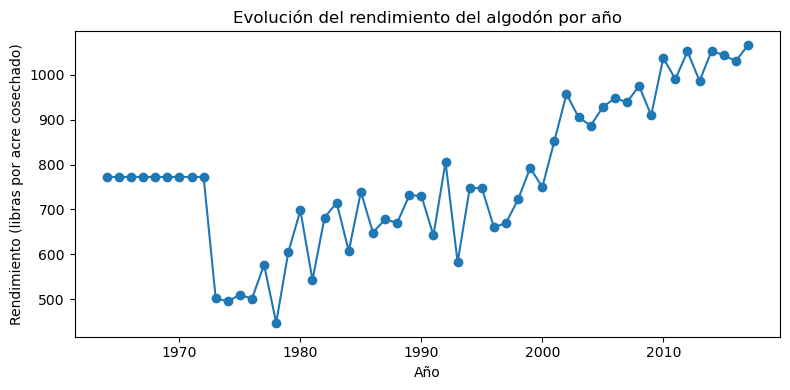

In [10]:
#Evolución del rendimiento del algodón por año
rendimiento_anual = df.groupby("Year")[ "Lint Yield (Pounds/Harvested Acre)"].mean()

plt.figure(figsize=(8, 4))
plt.plot(rendimiento_anual.index, rendimiento_anual.values, marker="o")
plt.title("Evolución del rendimiento del algodón por año")
plt.xlabel("Año")
plt.ylabel("Rendimiento (libras por acre cosechado)")
plt.tight_layout()
plt.show()

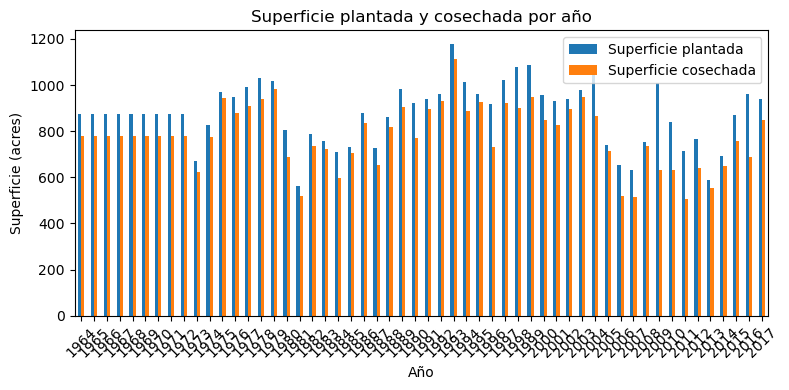

In [11]:
#Superficie plantada vs. superficie cosechada
superficie_anual = df.groupby("Year")[["Area Planted (acres)", "Harvested Area (acres)"]].mean()

superficie_anual.plot(kind="bar", figsize=(8, 4))
plt.title("Superficie plantada y cosechada por año")
plt.xlabel("Año")
plt.ylabel("Superficie (acres)")
plt.legend(["Superficie plantada", "Superficie cosechada"])
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

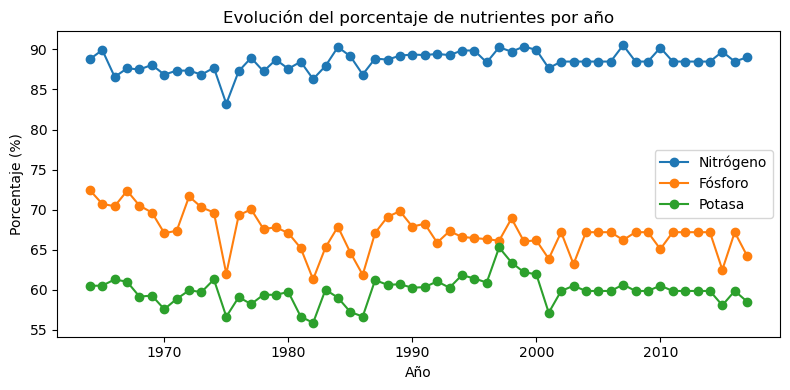

In [12]:
#Evolución del porcentaje de nutrientes
nutrientes_porcentaje = df.groupby("Year")[    ["Nitrogen (%)", "Phosphorous (%)", "Potash (%)"]].mean()

nutrientes_porcentaje.plot(kind="line", marker="o", figsize=(8, 4))
plt.title("Evolución del porcentaje de nutrientes por año")
plt.xlabel("Año")
plt.ylabel("Porcentaje (%)")
plt.legend(["Nitrógeno", "Fósforo", "Potasa"])
plt.tight_layout()
plt.show()

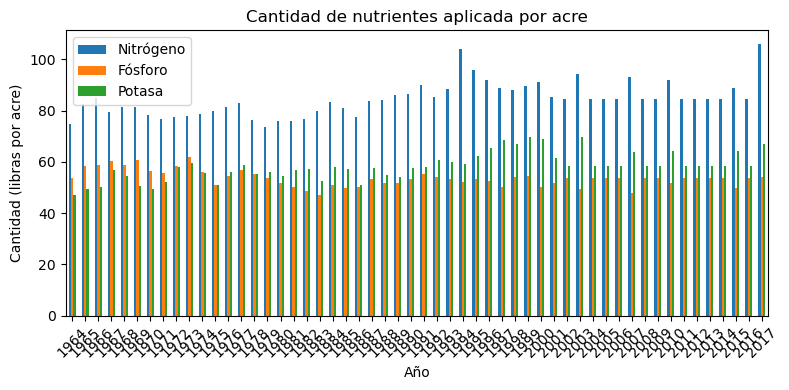

In [13]:
# Cantidad de nutrientes por acre
nutrientes_acre = df.groupby("Year")[["Nitrogen (Pounds/Acre)","Phosphorous (Pounds/Acre)","Potash (Pounds/Acre)"]].mean()

nutrientes_acre.plot(kind="bar", figsize=(8, 4))
plt.title("Cantidad de nutrientes aplicada por acre")
plt.xlabel("Año")
plt.ylabel("Cantidad (libras por acre)")
plt.legend(["Nitrógeno", "Fósforo", "Potasa"])
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

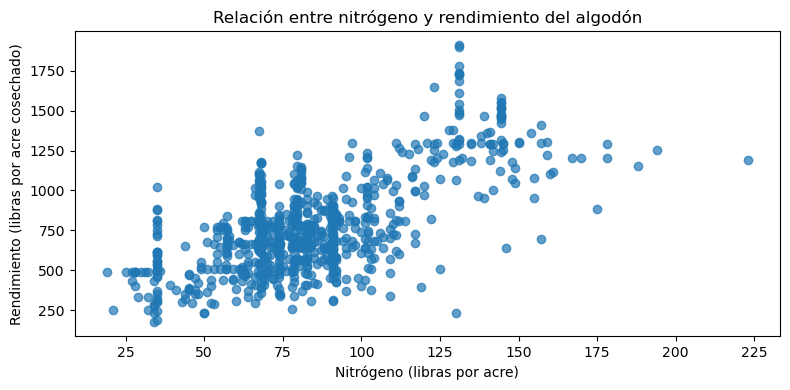

In [14]:
#  Relación entre nitrógeno y rendimiento
plt.figure(figsize=(8, 4))
plt.scatter( df["Nitrogen (Pounds/Acre)"],df["Lint Yield (Pounds/Harvested Acre)"],alpha=0.7)
plt.title("Relación entre nitrógeno y rendimiento del algodón")
plt.xlabel("Nitrógeno (libras por acre)")
plt.ylabel("Rendimiento (libras por acre cosechado)")
plt.tight_layout()
plt.show()

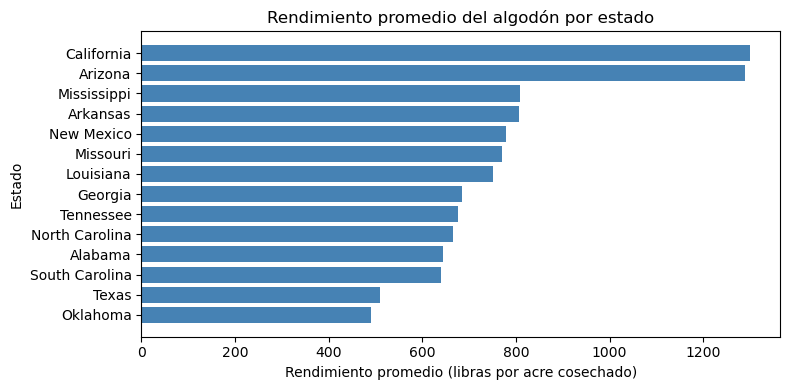

In [15]:
# Rendimiento promedio por estado
rendimiento_estado = df.groupby("State")[ "Lint Yield (Pounds/Harvested Acre)"].mean().sort_values()

plt.figure(figsize=(8, 4))
plt.barh(rendimiento_estado.index, rendimiento_estado.values,  color="steelblue")
plt.title("Rendimiento promedio del algodón por estado")
plt.xlabel("Rendimiento promedio (libras por acre cosechado)")
plt.ylabel("Estado")
plt.tight_layout()
plt.show()

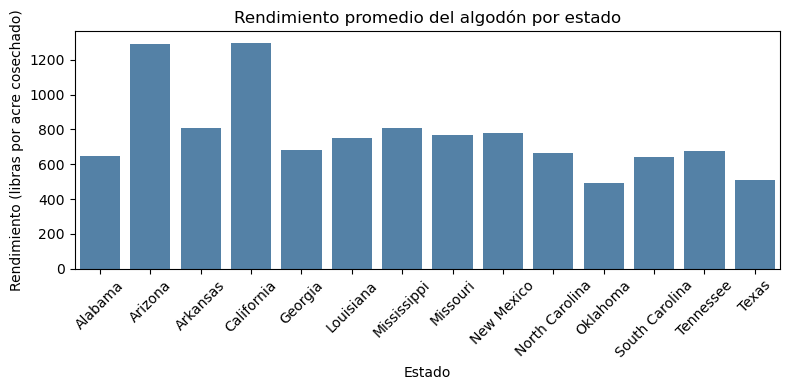

In [16]:
plt.figure(figsize=(8, 4))

sns.barplot( data=df,x="State",y="Lint Yield (Pounds/Harvested Acre)",errorbar=None,color="steelblue")

plt.title("Rendimiento promedio del algodón por estado")
plt.xlabel("Estado")
plt.ylabel("Rendimiento (libras por acre cosechado)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

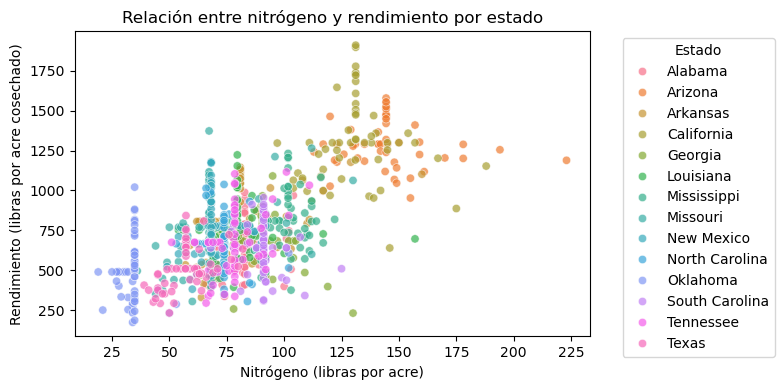

In [17]:
plt.figure(figsize=(8,4))

sns.scatterplot( data=df,x="Nitrogen (Pounds/Acre)",y="Lint Yield (Pounds/Harvested Acre)",hue="State",alpha=0.7)

plt.title("Relación entre nitrógeno y rendimiento por estado")
plt.xlabel("Nitrógeno (libras por acre)")
plt.ylabel("Rendimiento (libras por acre cosechado)")
plt.legend(title="Estado", bbox_to_anchor=(1.05, 1), loc="upper left")
plt.tight_layout()
plt.show()

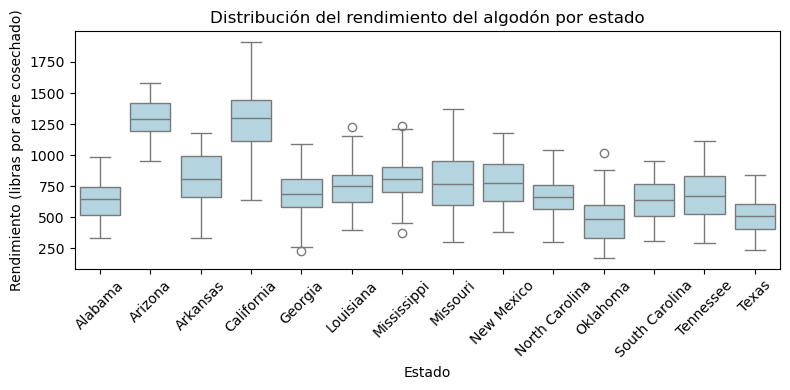

In [18]:
plt.figure(figsize=(8, 4))

sns.boxplot(data=df,x="State",y="Lint Yield (Pounds/Harvested Acre)",color="lightblue")

plt.title("Distribución del rendimiento del algodón por estado")
plt.xlabel("Estado")
plt.ylabel("Rendimiento (libras por acre cosechado)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

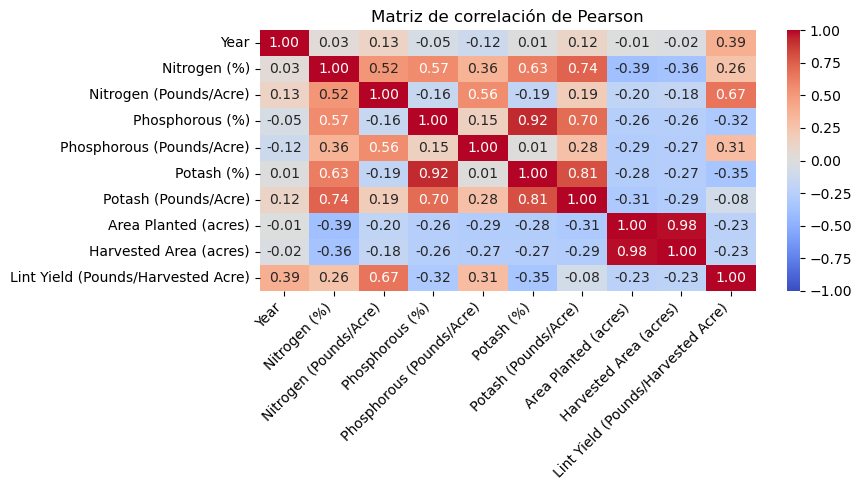

In [19]:
variables = ["Year","Nitrogen (%)","Nitrogen (Pounds/Acre)","Phosphorous (%)","Phosphorous (Pounds/Acre)","Potash (%)","Potash (Pounds/Acre)","Area Planted (acres)","Harvested Area (acres)",
             "Lint Yield (Pounds/Harvested Acre)"]

# Calcular correlación de Pearson
correlacion_pearson = df[variables].corr(method="pearson")

plt.figure(figsize=(9, 5))

sns.heatmap(correlacion_pearson,annot=True,cmap="coolwarm",fmt=".2f",vmin=-1,vmax=1,center=0)

plt.title("Matriz de correlación de Pearson")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

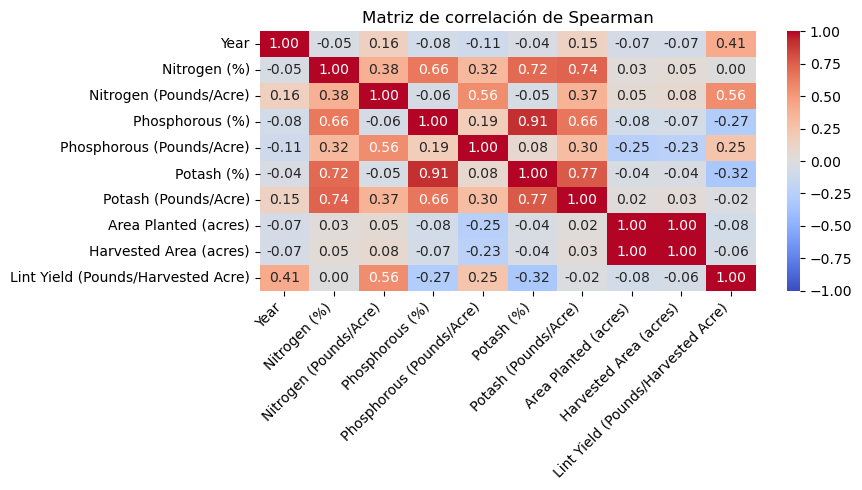

In [20]:
correlacion_spearman = df[variables].corr(method="spearman")

plt.figure(figsize=(9, 5))

sns.heatmap(correlacion_spearman,annot=True,cmap="coolwarm",fmt=".2f",vmin=-1,vmax=1,center=0)

plt.title("Matriz de correlación de Spearman")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

### Preentrenamieto & Desarrollo

In [21]:
objetivo = "Lint Yield (Pounds/Harvested Acre)"

x = df.drop(columns=[objetivo])
y = df[objetivo]

In [22]:
# Convertir State en variables numéricas
x = pd.get_dummies(x, columns=["State"], drop_first=True)

In [23]:
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)

In [24]:
print(x_train.shape, x_test.shape, y_train.shape, y_test.shape)

(604, 22) (152, 22) (604,) (152,)


In [25]:
modelos = {
    "Regresión Lineal": LinearRegression(),
    "Random Forest": RandomForestRegressor(n_estimators=100, random_state=42),
    "Gradient Boosting": GradientBoostingRegressor(random_state=42)
}

resultados = []
predicciones = {}

In [26]:
for nombre, modelo in modelos.items():
    modelo.fit(x_train, y_train)

    pred_train = modelo.predict(x_train)
    pred_test = modelo.predict(x_test)

    predicciones[nombre] = pred_test

    for conjunto, real, pred in [
        ("Train", y_train, pred_train),
        ("Test", y_test, pred_test)
    ]:
        resultados.append({
            "Modelo": nombre,
            "Conjunto": conjunto,
            "RMSE": mean_squared_error(real, pred) ** 0.5,
            "MAE": mean_absolute_error(real, pred),
            "R2": r2_score(real, pred)
        })

metricas = pd.DataFrame(resultados)

print(metricas.round(3))

              Modelo Conjunto     RMSE      MAE     R2
0   Regresión Lineal    Train  143.725  120.408  0.768
1   Regresión Lineal     Test  152.598  127.944  0.757
2      Random Forest    Train   45.634   33.053  0.977
3      Random Forest     Test  116.305   78.389  0.859
4  Gradient Boosting    Train   79.563   60.264  0.929
5  Gradient Boosting     Test  107.465   78.425  0.879


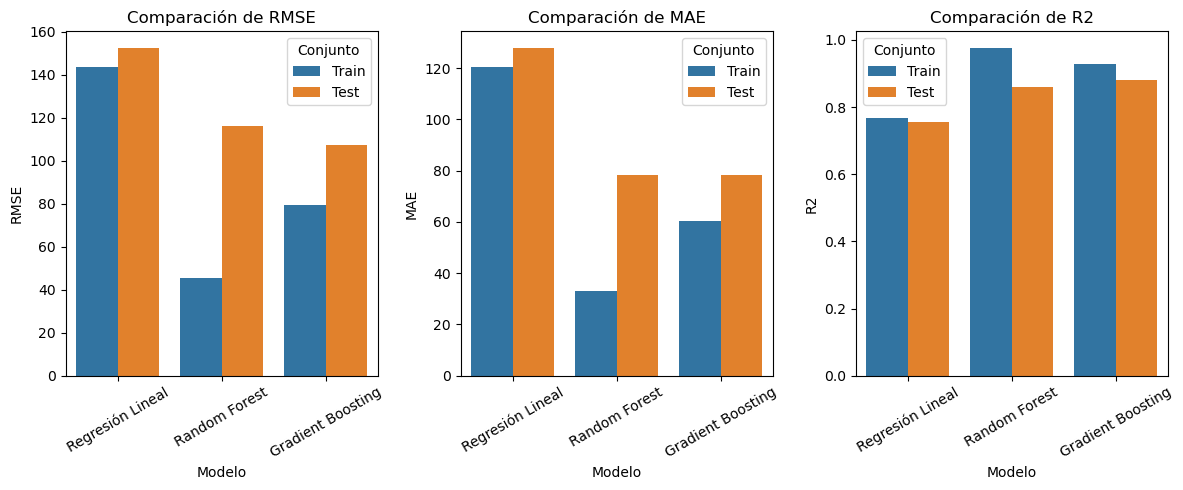

In [27]:
fig, axes = plt.subplots(1, 3, figsize=(12, 5))

for ax, metrica in zip(axes, ["RMSE", "MAE", "R2"]):
    sns.barplot(  data=metricas,  x="Modelo", y=metrica, hue="Conjunto", ax=ax)
    ax.set_title(f"Comparación de {metrica}")
    ax.tick_params(axis="x", rotation=30)

plt.tight_layout()
plt.show()

In [28]:
metricas_test = metricas[metricas["Conjunto"] == "Test"]

mejor_nombre = metricas_test.sort_values("RMSE").iloc[0]["Modelo"]
mejor_modelo = modelos[mejor_nombre]

print("Mejor modelo:", mejor_nombre)

joblib.dump(mejor_modelo, "mejor_modelo_algodon.joblib")

Mejor modelo: Gradient Boosting


['mejor_modelo_algodon.joblib']

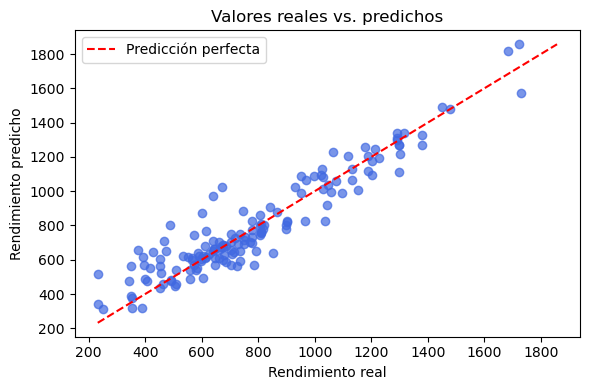

In [29]:
pred_test = mejor_modelo.predict(x_test)

# Gráfico 1: valores reales y predichos
plt.figure(figsize=(6, 4))

plt.scatter(y_test, pred_test, alpha=0.7, color="royalblue")

limite_min = min(y_test.min(), pred_test.min())
limite_max = max(y_test.max(), pred_test.max())

plt.plot([limite_min, limite_max],[limite_min, limite_max],"r--",label="Predicción perfecta")

plt.xlabel("Rendimiento real")
plt.ylabel("Rendimiento predicho")
plt.title("Valores reales vs. predichos")
plt.legend()
plt.tight_layout()
plt.show()

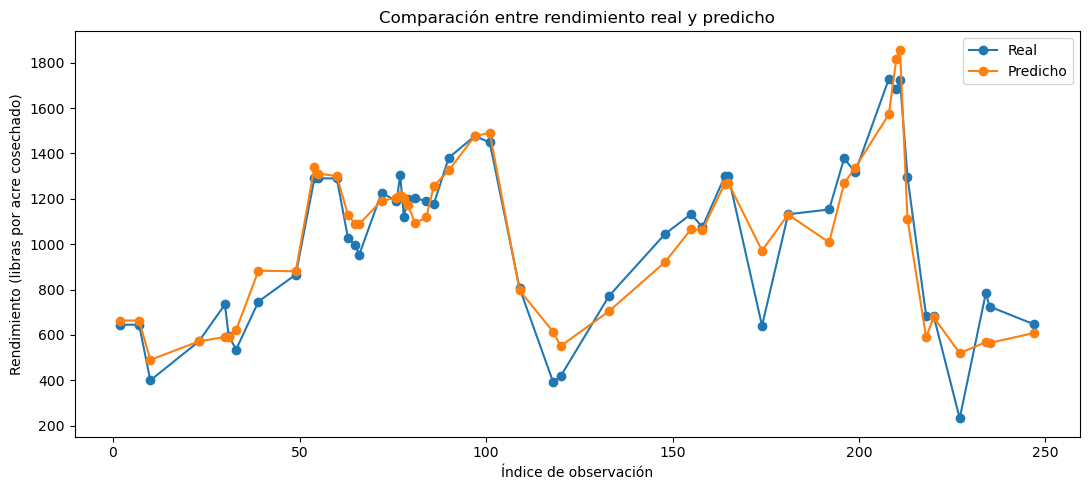

In [30]:
comparacion = pd.DataFrame({"Real": y_test, "Predicho": pred_test}).sort_index()

comparacion.iloc[:50].plot( figsize=(11, 5), marker="o")

plt.title("Comparación entre rendimiento real y predicho")
plt.xlabel("Índice de observación")
plt.ylabel("Rendimiento (libras por acre cosechado)")
plt.legend(["Real", "Predicho"])
plt.tight_layout()
plt.show()

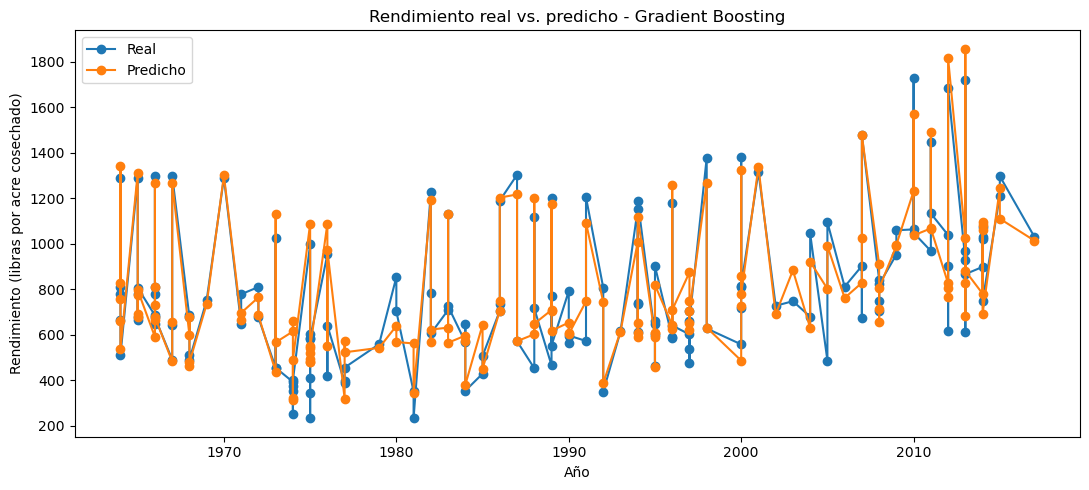

In [31]:
comparacion = pd.DataFrame({"Año": df.loc[x_test.index, "Year"],"Real": y_test,"Predicho": predicciones[mejor_nombre]}).sort_values("Año")

comparacion.plot( x="Año", y=["Real", "Predicho"], marker="o", figsize=(11, 5))

plt.title(f"Rendimiento real vs. predicho - {mejor_nombre}")
plt.xlabel("Año")
plt.ylabel("Rendimiento (libras por acre cosechado)")
plt.tight_layout()
plt.show()

Ejemplo de carga del modelo

In [32]:
# Cargar el modelo guardado
modelo_cargado = joblib.load("mejor_modelo_algodon.joblib")

# Seleccionar dos registros de prueba
pruebas = x_test.iloc[:2]


In [33]:
# Predecir
predicciones_prueba = modelo_cargado.predict(pruebas)

# Comparar con los valores reales
resultado_pruebas = pd.DataFrame({
    "Rendimiento real": y_test.loc[pruebas.index].values,
    "Rendimiento predicho": predicciones_prueba
}, index=pruebas.index)

resultado_pruebas["Error absoluto"] = (
    resultado_pruebas["Rendimiento real"]
    - resultado_pruebas["Rendimiento predicho"]
).abs()

print("PRUEBAS DEL MODELO CARGADO")
print(resultado_pruebas.round(2))

PRUEBAS DEL MODELO CARGADO
     Rendimiento real  Rendimiento predicho  Error absoluto
408             737.0                652.78           84.22
97             1477.0               1477.00            0.00


Hiperparametrizacion

In [34]:
# Definir los modelos y sus hiperparámetros
busquedas = {
    "Regresión Lineal": ( LinearRegression(), {"fit_intercept": [True, False]} ),
    "Random Forest": (RandomForestRegressor(random_state=42), { "n_estimators": [100, 200],"max_depth": [None, 10, 20],"min_samples_split": [2, 5]}),
    "Gradient Boosting": ( GradientBoostingRegressor(random_state=42), {"n_estimators": [100, 200],"learning_rate": [0.05, 0.1],"max_depth": [2, 3]})
}

mejores_modelos = {}
resultados_busqueda = []

In [35]:
for nombre, (algoritmo, parametros) in busquedas.items():

    busqueda = GridSearchCV(algoritmo,parametros,cv=3,scoring="neg_root_mean_squared_error",n_jobs=-1 )

    busqueda.fit(x_train, y_train)

    mejores_modelos[nombre] = busqueda.best_estimator_

    resultados_busqueda.append({
        "Modelo": nombre,
        "Mejor RMSE validación": -busqueda.best_score_,
        "Mejores parámetros": busqueda.best_params_
    })

    print(f"\n{nombre}")
    print("Mejores parámetros:", busqueda.best_params_)
    print("RMSE de validación:", round(-busqueda.best_score_, 3))

print("\nRESUMEN DE HIPERPARAMETRIZACIÓN")
print(pd.DataFrame(resultados_busqueda).to_string(index=False))


Regresión Lineal
Mejores parámetros: {'fit_intercept': True}
RMSE de validación: 150.035

Random Forest
Mejores parámetros: {'max_depth': 10, 'min_samples_split': 2, 'n_estimators': 100}
RMSE de validación: 128.142

Gradient Boosting
Mejores parámetros: {'learning_rate': 0.05, 'max_depth': 3, 'n_estimators': 200}
RMSE de validación: 122.696

RESUMEN DE HIPERPARAMETRIZACIÓN
           Modelo  Mejor RMSE validación                                             Mejores parámetros
 Regresión Lineal             150.035498                                        {'fit_intercept': True}
    Random Forest             128.142337 {'max_depth': 10, 'min_samples_split': 2, 'n_estimators': 100}
Gradient Boosting             122.696073   {'learning_rate': 0.05, 'max_depth': 3, 'n_estimators': 200}


In [36]:
resultados_finales = []
predicciones_finales = {}

for nombre, modelo in mejores_modelos.items():

    pred_train = modelo.predict(x_train)
    pred_test = modelo.predict(x_test)

    predicciones_finales[nombre] = pred_test

    for conjunto, reales, pred in [
        ("Train", y_train, pred_train),
        ("Test", y_test, pred_test)
    ]:
        resultados_finales.append({
            "Modelo": nombre,
            "Conjunto": conjunto,
            "RMSE": mean_squared_error(reales, pred) ** 0.5,
            "MAE": mean_absolute_error(reales, pred),
            "R2": r2_score(reales, pred)
        })

metricas_finales = pd.DataFrame(resultados_finales)

print("\nMÉTRICAS DE LOS MODELOS OPTIMIZADOS")
print(metricas_finales.round(3).to_string(index=False))


MÉTRICAS DE LOS MODELOS OPTIMIZADOS
           Modelo Conjunto    RMSE     MAE    R2
 Regresión Lineal    Train 143.725 120.408 0.768
 Regresión Lineal     Test 152.598 127.944 0.757
    Random Forest    Train  64.706  47.277 0.953
    Random Forest     Test 115.894  77.880 0.860
Gradient Boosting    Train  78.878  59.994 0.930
Gradient Boosting     Test 105.576  77.153 0.883


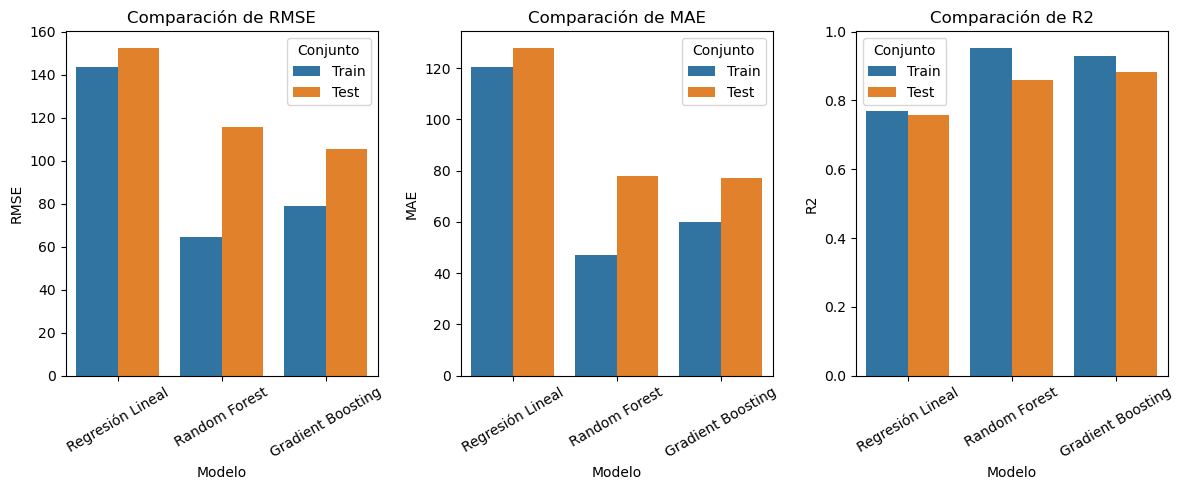

In [37]:
fig, axes = plt.subplots(1, 3, figsize=(12, 5))

for ax, metrica in zip(axes, ["RMSE", "MAE", "R2"]):

    sns.barplot(data=metricas_finales, x="Modelo", y=metrica, hue="Conjunto", ax=ax)

    ax.set_title(f"Comparación de {metrica}")
    ax.tick_params(axis="x", rotation=30)

plt.tight_layout()
plt.show()

In [38]:
tabla_validacion = pd.DataFrame(resultados_busqueda)

mejor_nombre = tabla_validacion.sort_values("Mejor RMSE validación").iloc[0]["Modelo"]

mejor_modelo = mejores_modelos[mejor_nombre]

print("Mejor modelo optimizado:", mejor_nombre)
print("RMSE de validación:",
      round(
          tabla_validacion.set_index("Modelo")
          .loc[mejor_nombre, "Mejor RMSE validación"], 3
      ))

Mejor modelo optimizado: Gradient Boosting
RMSE de validación: 122.696


In [39]:
joblib.dump(mejor_modelo, "mejor_modelo_algodon_optimizado.joblib")

print("Modelo guardado correctamente.")

Modelo guardado correctamente.



RENDIMIENTO REAL VS. PREDICHO
         Real  Predicho
Año                    
1964   810.73    814.51
1965   843.12    845.86
1966   815.10    792.79
1967   809.79    800.84
1968   589.84    548.06
1969   751.67    735.98
1970  1290.29   1308.34
1971   711.23    693.92
1972   742.36    723.29
1973   645.00    707.97
1974   354.20    471.17
1975   535.00    593.02
1976   670.00    872.42
1977   413.33    467.92
1979   558.00    544.61
1980   777.50    607.49
1981   291.00    463.59
1982   872.00    797.99
1983   855.00    768.85
1984   522.00    517.83
1985   467.00    549.35
1986   877.00    890.08
1987   937.00    902.53
1988   762.00    819.41
1989   747.50    805.75
1990   651.00    630.34
1991   888.00    922.65
1992   577.50    578.99
1993   614.00    617.23
1994   884.80    790.91
1995   653.60    611.12
1996   748.25    806.30
1997   595.40    708.96
1998  1002.50    945.48
2000   855.80    820.86
2001  1317.00   1338.59
2002   727.00    704.35
2003   747.00    900.20
2004   86

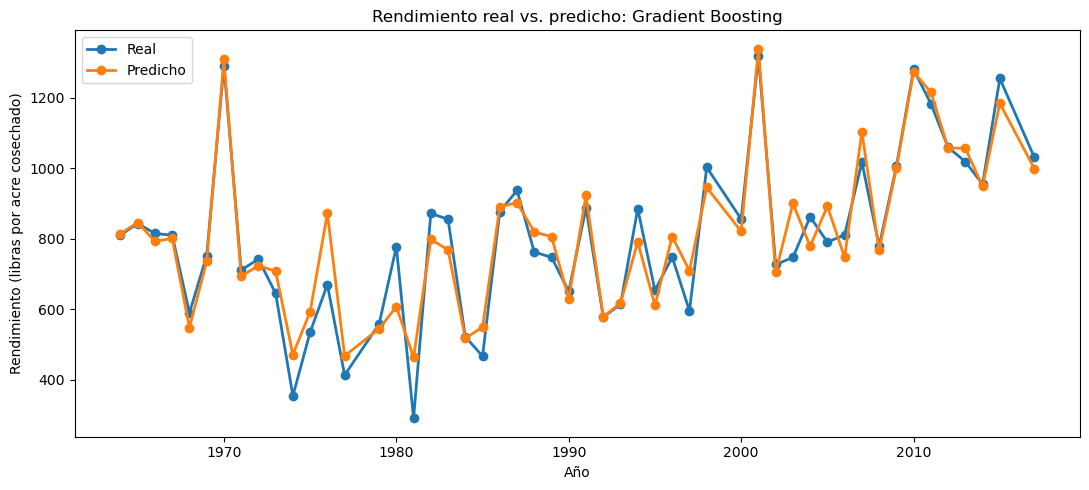

In [40]:
comparacion = pd.DataFrame({"Año": df.loc[x_test.index, "Year"],"Real": y_test,"Predicho": mejor_modelo.predict(x_test)})

# Promedio por año, en caso de que haya varios estados
serie = comparacion.groupby("Año")[["Real", "Predicho"]].mean()

print("\nRENDIMIENTO REAL VS. PREDICHO")
print(serie.round(2))

serie.plot(figsize=(11, 5),marker="o",linewidth=2)

plt.title(f"Rendimiento real vs. predicho: {mejor_nombre}")
plt.xlabel("Año")
plt.ylabel("Rendimiento (libras por acre cosechado)")
plt.legend(["Real", "Predicho"])
plt.tight_layout()
plt.show()


IMPORTANCIA DE LAS VARIABLES
                 Variable  Importancia
   Nitrogen (Pounds/Acre)     154.0378
                     Year     111.4740
               Potash (%)      76.4881
     Area Planted (acres)      25.2763
   Harvested Area (acres)      17.5475
         State_California       8.5172
     Potash (Pounds/Acre)       6.1798
          Phosphorous (%)       5.6466
             Nitrogen (%)       4.1957
           State_Oklahoma       1.2324
           State_Arkansas       0.5800
     State_South Carolina       0.0657
Phosphorous (Pounds/Acre)       0.0371
              State_Texas       0.0046
            State_Georgia       0.0000
          State_Louisiana       0.0000
        State_Mississippi       0.0000
         State_New Mexico       0.0000
     State_North Carolina       0.0000
            State_Arizona      -0.0087
          State_Tennessee      -0.1360
           State_Missouri      -0.2100


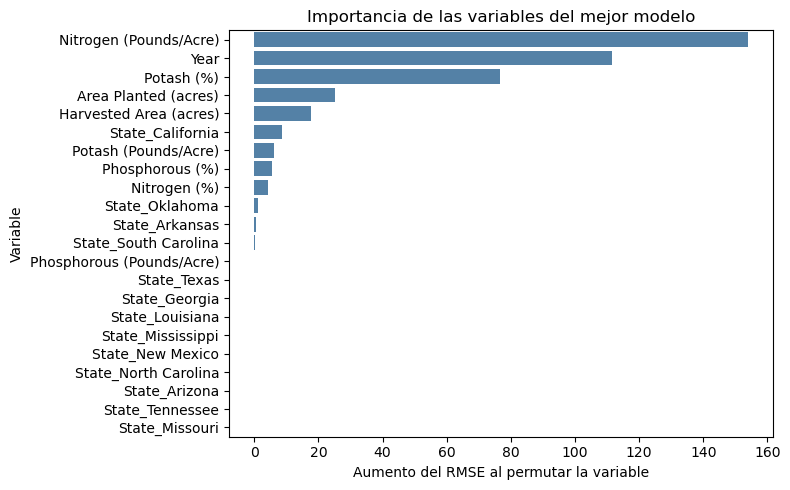

In [41]:
importancia = permutation_importance(
    mejor_modelo,x_test, y_test, scoring="neg_root_mean_squared_error",n_repeats=10,random_state=42)

tabla_importancia = pd.DataFrame({
    "Variable": x_test.columns,
    "Importancia": importancia.importances_mean
}).sort_values("Importancia", ascending=False)

print("\nIMPORTANCIA DE LAS VARIABLES")
print(tabla_importancia.round(4).to_string(index=False))

plt.figure(figsize=(8, 5))

sns.barplot(data=tabla_importancia,x="Importancia",y="Variable",color="steelblue")

plt.title("Importancia de las variables del mejor modelo")
plt.xlabel("Aumento del RMSE al permutar la variable")
plt.ylabel("Variable")
plt.tight_layout()
plt.show()

### Conclusion

El dataset tiene 756 filas (14 estados × 54 años, 1964-2017). La variable objetivo tiene **126 nulos**, que son exactamente 9 años × 14 estados. Los nutrientes tienen unos 288 nulos.

El notebook ejecuta `df.fillna(df.groupby('State').transform('mean'))` sobre todo el dataframe, y en ese momento la columna objetivo todavía está incluida. Por lo tanto, unas 126 filas tienen un **rendimiento imputado con la media del estado**. Se nota en el primer gráfico: el rendimiento es plano (~772) entre 1964 y 1972 y cae de golpe en 1973. Ese salto es un artefacto de la imputación, no un fenómeno agronómico.

Esas filas quedan repartidas entre train y test, así que parte del test mide si el modelo adivina una media de estado y no un rendimiento real. Esto afecta las métricas de todos los modelos y conviene tomarlas con cautela.

| Gráfico | Qué muestra | Comentario |
|---|---|---|
| Rendimiento por año | Tendencia creciente de ~500-700 a ~1050 lb/acre desde 1973 | Año es muy informativo, pero el tramo 1964-72 es artificial (ver sección 1). |
| Superficie plantada vs. cosechada | Casi iguales, con una brecha chica y estable | Correlación de 0,98 entre ambas. El eje X con 54 etiquetas se amontona. |
| % de nutrientes por año | N ~88% estable, P ~65-70% y K ~60% con leve baja | Es un promedio entre estados, así que oculta diferencias regionales. |
| Libras de nutrientes por acre | El N sube de ~75 a ~85-105 | Es el nutriente con la tendencia más clara. |
| Nitrógeno vs. rendimiento | Relación positiva con mucha dispersión | En el scatter por estado se ve que parte de la relación es de grupos: California y Arizona tienen más N y más rendimiento. |
| Barras y boxplot por estado | California y Arizona (~1300) duplican a Oklahoma, Texas y Alabama (~500-650) | Es la señal más fuerte del dataset (probablemente riego). Casi no hay superposición en los boxplots. |
| Correlación Pearson y Spearman | N lb/acre es el mejor predictor lineal (0,67 y 0,56). Año: 0,39 y 0,41. Potasa %: -0,35 y -0,32 | P% y potasa % están en 0,92 entre sí; área plantada y cosechada en 0,98. La correlación del área con el rendimiento pasa de -0,23 (Pearson) a -0,08 (Spearman), lo que indica influencia de outliers (máx. 7.850 acres). |

**Gráficos de resultados**
- **Real vs. predicho:** los puntos siguen bien la diagonal, pero con más dispersión a rendimientos altos. El modelo subestima los extremos (un real de ~1730 se predice en ~1570; un real de ~230 se predice en ~520). Es el efecto típico de regresión a la media.
- **Real vs. predicho por índice:** las líneas unen observaciones no consecutivas y sugieren una continuidad inexistente. Es más honesto con puntos sueltos.
- **Real vs. predicho por año (sin agregar):** hay varios estados por año, por lo que se produce un zigzag ilegible. La versión promediada por año de la celda final lo resuelve.
- **Importancia por permutación:** dominan N lb/acre (154), Año (111) y Potasa % (76). Las dummies de estado casi no aportan.

La potasa % probablemente actúa como sustituto del estado: Arizona, California, Nuevo México y Texas tienen potasa % baja y justo son estados de rendimiento extremo. Por eso `State_California` aporta poco, ya que su información está en otras columnas. La importancia no implica causalidad.

Split 80/20 aleatorio (604 train, 152 test).

| Modelo | RMSE train | RMSE test | MAE test | R² train | R² test |
|---|---|---|---|---|---|
| Regresión lineal | 143,7 | 152,6 | 127,9 | 0,768 | 0,757 |
| Random Forest | 45,6 | 116,3 | 78,4 | 0,977 | 0,859 |
| Gradient Boosting | 79,6 | 107,5 | 78,4 | 0,929 | 0,879 |

Gradient Boosting es el mejor en test. Su RMSE (~107) equivale a ~14% de la media del rendimiento (772) y ~34% de su desviación estándar (313).

- **Regresión lineal: underfitting (alto sesgo).** Train y test son casi iguales (R² 0,768 vs 0,757), pero el error es alto en ambos. No captura la no linealidad (tendencia temporal, saturación del N, efecto regional).
- **Random Forest por defecto: overfitting claro.** El RMSE de test es 2,5 veces el de train (45,6 → 116,3) y el R² cae 0,118.
- **Gradient Boosting por defecto: overfitting moderado.** El RMSE de test es 1,35 veces el de train y el R² cae 0,050. Es el que mejor generaliza.

Grilla: 2, 12 y 8 combinaciones, con 3-fold CV y scoring RMSE.
- **Regresión lineal:** `fit_intercept=True`
- **Random Forest:** `max_depth=10`, `min_samples_split=2`, `n_estimators=100`
- **Gradient Boosting:** `learning_rate=0.05`, `max_depth=3`, `n_estimators=200`

| Modelo | | RMSE train | RMSE test | MAE test | R² test | Brecha R² | Ratio test/train |
|---|---|---|---|---|---|---|---|
| Lineal | antes y después | 143,7 | 152,6 | 127,9 | 0,757 | 0,011 | 1,06 |
| Random Forest | antes | 45,6 | 116,3 | 78,4 | 0,859 | 0,118 | 2,55 |
| Random Forest | después | 64,7 | 115,9 | 77,9 | 0,860 | 0,093 | 1,79 |
| Gradient Boosting | antes | 79,6 | 107,5 | 78,4 | 0,879 | 0,050 | 1,35 |
| Gradient Boosting | después | 78,9 | 105,6 | 77,2 | 0,883 | 0,047 | 1,34 |

- **Lineal:** sin cambios, porque su único hiperparámetro no incide en el resultado.
- **Random Forest:** limitar la profundidad redujo el ajuste en train (RMSE 45,6 → 64,7), pero en test casi no mejoró (-0,4 de RMSE, -0,4%). Sigue sobreajustado (brecha de R² de 0,093).
- **Gradient Boosting:** mejora pequeña en test (-1,9 de RMSE, -1,8%; +0,004 de R²) y el overfitting prácticamente no cambia.
- **Contra la regresión lineal:** el GB optimizado reduce el RMSE de test un 31%, y casi todo ese salto viene de cambiar de algoritmo, no de tunear.

El ranking no cambia (GB > RF > Lineal). Con un test de 152 filas y un único split, una mejora de ~2 de RMSE probablemente está dentro del ruido. Además, el GB eligió valores en el borde de la grilla (`n_estimators=200`, `learning_rate=0.05`), así que el óptimo podría estar más allá.

1. **Imputación del target:** eliminar las filas sin rendimiento y no imputar nunca la variable objetivo.
2. **Split aleatorio en datos panel:** estado y año consecutivos se parecen mucho, lo que vuelve optimistas las métricas. Validar con `GroupKFold` por estado o con un corte temporal.
3. **Imputar antes del split:** las medias por estado usan información del test. Conviene usar un `Pipeline`.
4. **Imputar nutrientes con la media del estado** ignora la tendencia temporal. Una interpolación por año dentro de cada estado, o un indicador de dato faltante, sería más fiel.
5. **Una sola partición de test:** falta cross-validation con media y desvío para saber si las diferencias entre modelos son reales.
6. **Selección del mejor modelo:** en la primera parte se elige por RMSE de test; en la parte optimizada, por validación cruzada (lo correcto).
7. **Grilla:** para RF, explorar `min_samples_leaf` y `max_features`; para GB, más `n_estimators` con menor `learning_rate`, `subsample` y `min_samples_leaf`. También probar HistGradientBoosting, XGBoost o LightGBM.
8. **Variables:** falta una variable de riego, y un rezago (rendimiento del año anterior) podría ayudar. Área plantada/cosechada y P%/K% están muy correlacionadas.

**Conclusión general:** Gradient Boosting (con o sin tuning) es la mejor opción y la regresión lineal queda corta. Pero el mayor margen de mejora no está en los hiperparámetros, sino en limpiar el target imputado y usar una validación que respete la estructura estado/año.